# YAGO 4.5 KGE — notes and embedding visualizations

This notebook documents the `yago45-kge` example and visualizes the trained
**200-dimensional** entity/relation embeddings:

- **Data**: YAGO 4.5 Turtle → entity–entity triples (literals/labels dropped) →
  GestaltDB (RocksDB) ingest → CSR `SamplerSnapshot`.
- **Model**: trainable entity `[N,200]` + relation `[R,200]` tables → 2-step
  `tf_gnns.GraphNetMPNN_MLP` encoder → DistMult scorer `sum(h_s · r · h_o)`,
  InfoNCE loss over 1 positive + 8 hard negatives from `SamplerEngine`.
- **Training**: compiled `@tf.function` step; `tf.data` feed from array-backed CSR
  (no KV reads in the hot path).
- **Runs**: `data/yago45` (tiny: 352k triples / 300k entities / 57 relations,
  5k steps) and `data/yago45_facts` (8.0M triples / 3.64M entities / 27 relations,
  8k steps). Set `USE_FACTS = True` below to visualize the facts run
  (needs ~4 GB RAM for the entity matrix).


In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import polars as pl

USE_FACTS = False  # set True for the 3.6M-entity facts run

# Works both in the workspace layout (data at repo root) and in a
# self-contained example checkout (data inside the example dir).
here = Path.cwd()
def _example_root(start):
    for p in [start, *start.parents]:
        if (p / "yago").exists() and (p / "scripts").exists():
            return p
    return start
ex = _example_root(here)
name = "yago45_facts" if USE_FACTS else "yago45"
cands = [(ex / ".." / "data" / name).resolve(), ex / "data" / name]
DATA_ROOT = next(p for p in cands if p.exists())
ART = DATA_ROOT / "artifacts"
print("DATA_ROOT:", DATA_ROOT)

DATA_ROOT: /home/charilaos/Workspace/gestalt-example/data/yago45


In [2]:
import json
meta = json.loads((ART / "metadata.json").read_text())
print(f"nodes={meta['num_nodes']:,} edges={meta['num_edges']:,} relations={meta['num_relations']}")
node_map = pl.read_parquet(ART / "node_map.parquet").sort("node_int")
rel_map = pl.read_parquet(ART / "relation_map.parquet").sort("rel_int")
print(node_map.head(3))
print(rel_map)

nodes=299,739 edges=351,934 relations=57
shape: (3, 3)
┌──────────┬─────────────────────────┬────────┐
│ node_int ┆ node_id                 ┆ kind   │
│ ---      ┆ ---                     ┆ ---    │
│ u32      ┆ str                     ┆ str    │
╞══════════╪═════════════════════════╪════════╡
│ 0        ┆ yago:Barware_Q117207848 ┆ Entity │
│ 1        ┆ yago:Concubinage        ┆ Entity │
│ 2        ┆ yago:Font               ┆ Entity │
└──────────┴─────────────────────────┴────────┘
shape: (57, 3)
┌─────────┬────────────────────┬────────┐
│ rel_int ┆ edge_type          ┆ len    │
│ ---     ┆ ---                ┆ ---    │
│ u32     ┆ str                ┆ u32    │
╞═════════╪════════════════════╪════════╡
│ 0       ┆ rdf:type           ┆ 66578  │
│ 1       ┆ rdfs:subClassOf    ┆ 163567 │
│ 2       ┆ schema:about       ┆ 883    │
│ 3       ┆ schema:actor       ┆ 4394   │
│ 4       ┆ schema:affiliation ┆ 17     │
│ …       ┆ …                  ┆ …      │
│ 52      ┆ yago:parentBody    ┆ 15 

## Relation distribution

Stratified sampling downstream relies on this skew (tiny is taxonomy-heavy;
facts is capped at 500k/relation for diversity).

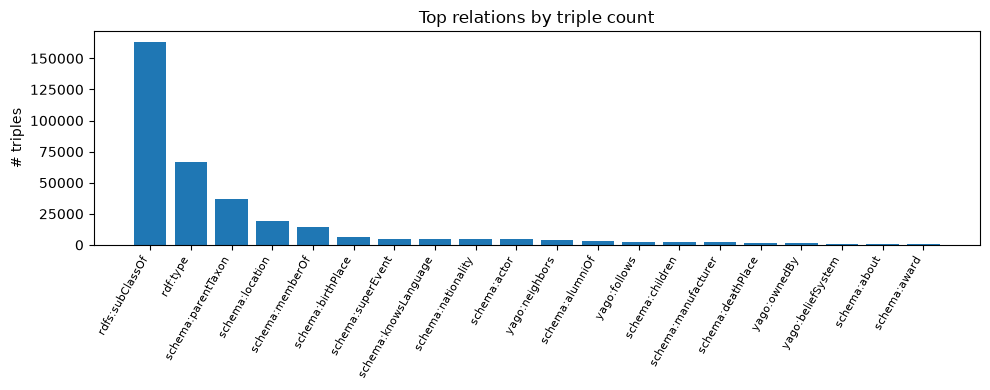

In [3]:
import matplotlib.pyplot as plt
top = rel_map.sort("len", descending=True).head(20)
names = top["edge_type"].to_list(); counts = top["len"].to_list()
plt.figure(figsize=(10, 4))
plt.bar(range(len(names)), counts)
plt.xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
plt.ylabel("# triples"); plt.title("Top relations by triple count")
plt.tight_layout(); plt.show()

## Embedding stats and stratified subset

We sample entities stratified by their *dominant incident relation* so the
t-SNE plot tests whether the contrastive objective separated relational roles.


entity (299739, 200) relation (57, 200)
finite: True True
entity norm: mean=0.416 std=0.023


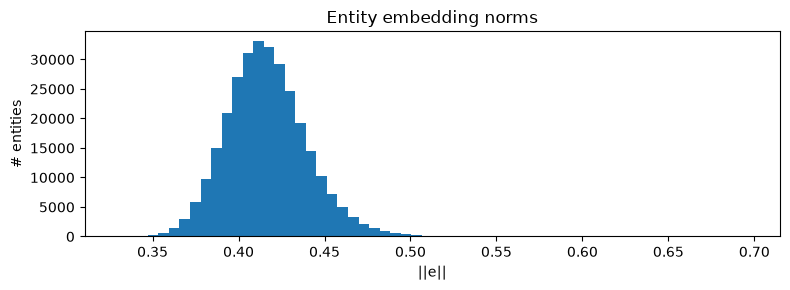

In [4]:
data = np.load(ART / "yago45_embeddings_200d.npz")
E, R = data["entity"].astype(np.float64), data["relation"].astype(np.float64)
ids = data["node_ids"].tolist()
print("entity", E.shape, "relation", R.shape)
assert E.shape[1] == 200 and R.shape[1] == 200
print("finite:", np.isfinite(E).all(), np.isfinite(R).all())
norms = np.linalg.norm(E, axis=1)
print(f"entity norm: mean={norms.mean():.3f} std={norms.std():.3f}")
plt.figure(figsize=(8, 3))
plt.hist(norms, bins=60); plt.xlabel("||e||"); plt.ylabel("# entities")
plt.title("Entity embedding norms"); plt.tight_layout(); plt.show()

In [5]:
triples = pl.scan_parquet(ART / "triples.parquet")
edom = (triples.group_by(["source", "edge_type"]).len()
        .sort(["source", "len"], descending=[False, True])
        .group_by("source").first()
        .collect())
print(f"entities with dominant relation: {len(edom):,}")
TOP_RELS = rel_map.sort("len", descending=True).head(8)["edge_type"].to_list()
print("plot relations:", TOP_RELS)
rng = np.random.default_rng(0)
PER_REL, sel_idx, sel_lab = 500, [], []
id_to_row = {nid: r for r, nid in enumerate(ids)}
for rel in TOP_RELS:
    cand = edom.filter(pl.col("edge_type") == rel)["source"].to_list()
    cand = [c for c in cand if c in id_to_row]
    take = rng.choice(cand, size=min(PER_REL, len(cand)), replace=False)
    sel_idx += [id_to_row[c] for c in take]; sel_lab += [rel] * len(take)
sel_idx = np.array(sel_idx); print("subset:", len(sel_idx))

entities with dominant relation: 284,912
plot relations: ['rdfs:subClassOf', 'rdf:type', 'schema:parentTaxon', 'schema:location', 'schema:memberOf', 'schema:birthPlace', 'schema:superEvent', 'schema:knowsLanguage']
subset: 4000


## t-SNE of the entity subset, colored by dominant relation

t-SNE done: (4000, 2)


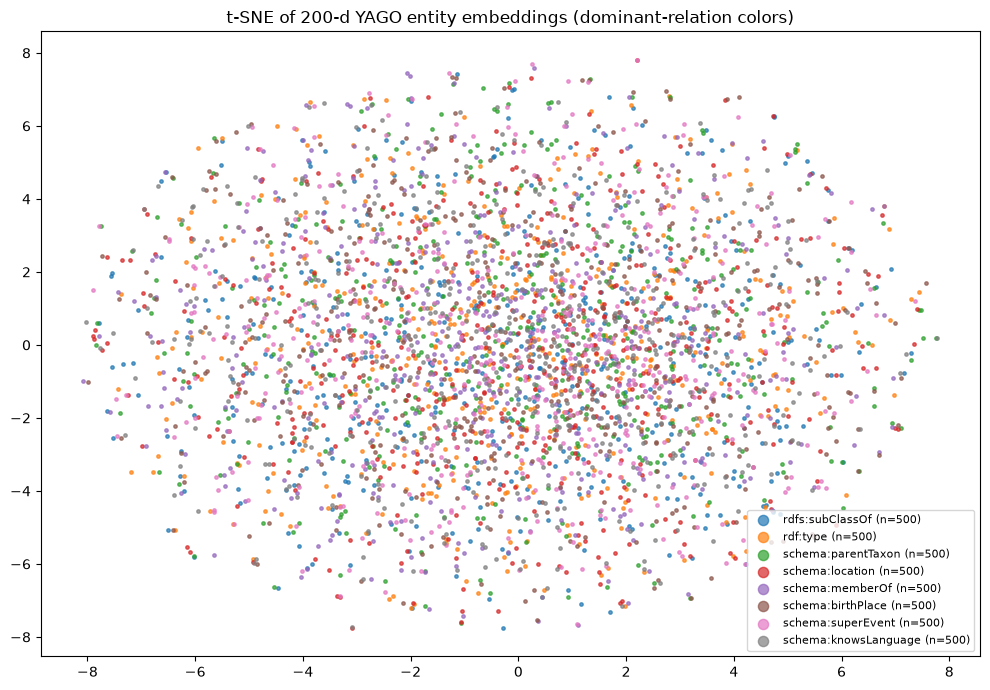

saved /home/charilaos/Workspace/gestalt-example/data/yago45/artifacts/tsne_subset.png


In [6]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
Xs = StandardScaler().fit_transform(E[sel_idx])
Z = TSNE(n_components=2, perplexity=30, max_iter=1000,
         learning_rate="auto", init="pca", random_state=0).fit_transform(Xs)
print("t-SNE done:", Z.shape)
plt.figure(figsize=(10, 7))
for rel in TOP_RELS:
    m = np.array(sel_lab) == rel
    if m.sum():
        plt.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.7, label=f"{rel} (n={m.sum()})")
plt.legend(markerscale=3, fontsize=8, loc="best")
plt.title("t-SNE of 200-d YAGO entity embeddings (dominant-relation colors)")
plt.tight_layout()
out = ART / "tsne_subset.png"; plt.savefig(out, dpi=120); plt.show()
print("saved", out)

## Relation–relation cosine structure

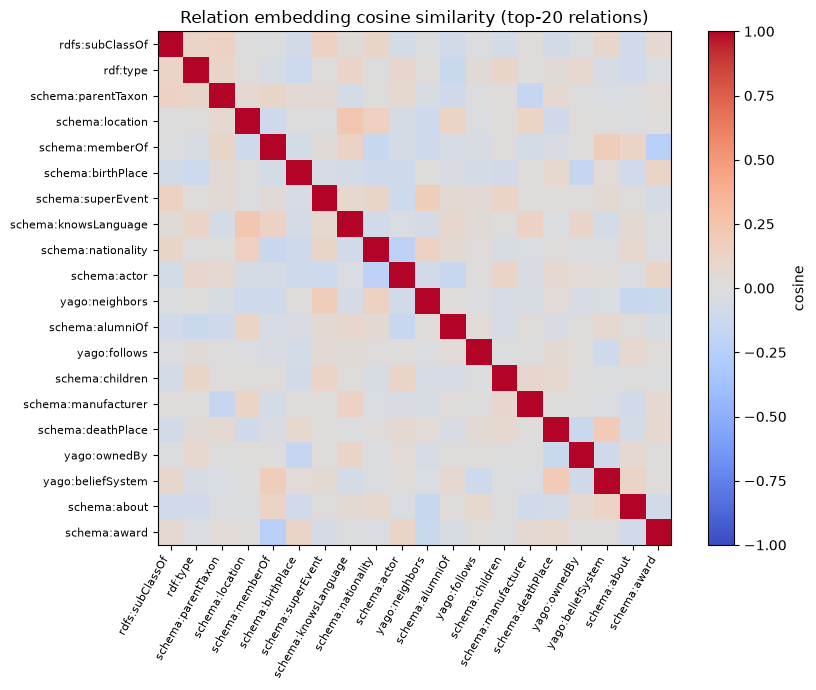

In [7]:
Rn = R / (np.linalg.norm(R, axis=1, keepdims=True) + 1e-9)
S = Rn @ Rn.T
order = np.argsort(-rel_map["len"].to_numpy())[:20]
labels = [rel_map["edge_type"][int(i)] for i in order]
plt.figure(figsize=(9, 7))
plt.imshow(S[np.ix_(order, order)], vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
plt.yticks(range(len(labels)), labels, fontsize=8)
plt.title("Relation embedding cosine similarity (top-20 relations)")
plt.colorbar(label="cosine"); plt.tight_layout(); plt.show()

## Nearest neighbors (spot check)

In [8]:
En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
def nn(name, k=5):
    i = ids.index(name)
    s = En @ En[i]; s[i] = -1
    return [(ids[j], round(float(s[j]), 4)) for j in np.argsort(-s)[:k]]
for q in [ids[i] for i in rng.choice(len(ids), size=3, replace=False)]:
    print(q)
    for nid, sc in nn(q): print(f"   {nid}  {sc}")

yago:Endonucleolytic_Cleavage_In_3_U0027_-Ets_Of_Tricistronic_Rrna_Transcript__U0028_Ssu-Rrna_U002C__5_U002E_8S_Rrna_U002C__Lsu-Rrna_U0029__Q22280911
   yago:Účinná_Lítost_Q2463684  0.3465
   yago:And_So_I_Watch_You_from_Afar__u0028_album_u0029_  0.3322
   yago:Ahmad_Deeb  0.3294
   yago:Compound_Eye_Morphogenesis_Q22295873  0.3283
   yago:Asiatherium  0.3282
yago:Antonia_Lyons
   yago:Annabel_Blanchard  0.3509
   yago:Alex_Young__u0028_footballer_u002C__born_1880_u0029_  0.3495
   yago:Adventure_Pack_I  0.3459
   yago:Aßling  0.3379
   yago:Anglican_Diocese_of_Montreal  0.3321
yago:Ali_Al_Kandari
   yago:Abbottabad_District  0.334
   yago:Alberto_Ángel_Zanchetta  0.3296
   yago:Alan_Dupont  0.3167
   yago:Squamous_Cell_Carcinoma_Of_The_Small_Intestine_Q55788136  0.3161
   yago:Aphelia_paleana  0.3152


## Notes / next steps

- NN cosine values (~0.3) and relation-mixed t-SNE regions reflect a short run
  (5k/8k steps, ~6% triple coverage). More steps, larger batches, and a
  relation-aware encoder tighten clusters.
- The exported `entity` matrix is the canonical 200-d artifact (row-aligned
  with `node_ids`); the GNN refines representations *during* training, and the
  base table is what gets updated end-to-end.
- To reproduce: `bash scripts/prepare.sh [--reset-db]` then
  `bash scripts/train.sh [--steps N --batch-size B]`; see `README.md`.
